## 1. Setup

In [1]:
from __future__ import annotations
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parents[1]
W4_SRC = PROJECT_ROOT / "workshops" / "w4" / "src"
for _p in (str(W4_SRC),):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from constants import CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR, SEED
from autoencoder.data_loader import load_w1_data
from train.train_ae  import load_checkpoint as ae_load_checkpoint, set_seed
from train.train_vae import load_checkpoint as vae_load_checkpoint
from evaluate.evaluate_ae  import ReconstructionEvaluator
from evaluate.evaluate_vae import VAEEvaluator
from evaluate.compare_reconstruction import ReconstructionComparator

RECON_DIR = RUNS_DIR / "reconstruction"
RECON_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cpu


## 2. Data

In [2]:
df, y_all, _, _, _, split = load_w1_data()

test_idx = split["test"]
df_test  = df.iloc[test_idx].reset_index(drop=True)
y_test   = y_all[test_idx]   # numpy array

# Preprocessor comes from ae_best.pt (same one used by both models)
_, _, prep, _, _ = ae_load_checkpoint(CHECKPOINTS_DIR / "ae_best.pt", DEVICE)
x_num_test, x_cat_test = prep.transform(df_test)

print(f"test samples : {len(x_num_test):,}")
print(f"churn rate   : {y_test.mean():.3%}")
print(f"numeric_dim  : {prep.numeric_dim}   input_dim: {prep.input_dim}")

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 63) | users in both labelled months: 881701
test samples : 970,960
churn rate   : 8.994%
numeric_dim  : 55   input_dim: 117


## 3. Load checkpoints

In [3]:
ae_model,  ae_cfg,  _, _, _ = ae_load_checkpoint( CHECKPOINTS_DIR / "ae_best.pt",  DEVICE)
vae_model, vae_cfg, _, _, _ = vae_load_checkpoint(CHECKPOINTS_DIR / "vae_best.pt", DEVICE)

print(f"AE  — z_dim={ae_cfg.z_dim}  hidden={ae_cfg.hidden_dims}")
print(f"VAE — z_dim={vae_cfg.z_dim}  beta={vae_cfg.beta}  hidden={vae_cfg.hidden_dims}")

ae_ev  = ReconstructionEvaluator(ae_model,  prep, DEVICE)
vae_ev = VAEEvaluator(vae_model, prep, DEVICE)

comp = ReconstructionComparator(
    models       = {"AE": ae_ev, "VAE": vae_ev},
    preprocessor = prep,
    device       = DEVICE,
)

AE  — z_dim=16  hidden=(64, 32)
VAE — z_dim=16  beta=1.0  hidden=(64, 32)


## 4. Summary table

In [4]:
summary = comp.summary_table(x_num_test, x_cat_test, y_test)
baseline = comp.baseline_row(x_cat_test)
full_table = pd.concat([summary, baseline], ignore_index=True)

print(full_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
full_table.to_csv(RECON_DIR / "recon_summary.csv", index=False)

                 model  mse_global  mse_normal  mse_churn  churn_to_normal_ratio  mean_pearson  median_pearson  acc_city  acc_registered_via  acc_last_payment_method_id
                    AE      0.0519      0.0417     0.1543                 3.6983        0.9764          0.9829    0.9998              0.9999                      0.9992
                   VAE      0.0943      0.0834     0.2052                 2.4618        0.9614          0.9679    0.6603              0.8944                      0.8671
Most-frequent baseline         NaN         NaN        NaN                    NaN           NaN             NaN    0.4558              0.5898                      0.5608


## 5. Error by class

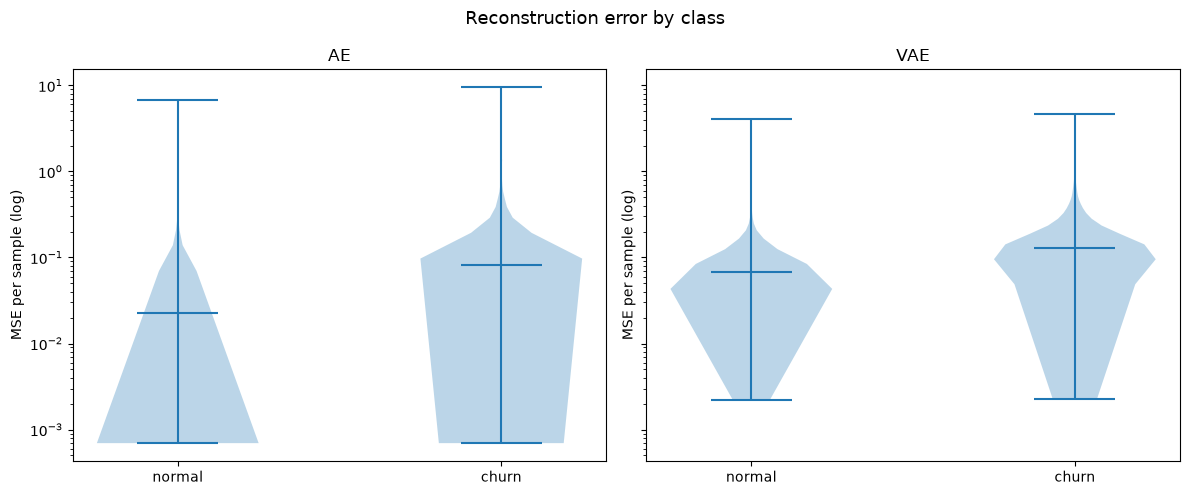


AE:
            mean    median
class                     
churn   0.154309  0.082620
normal  0.041724  0.022899

VAE:
            mean    median
class                     
churn   0.205212  0.128698
normal  0.083360  0.067222


In [5]:
ebc = comp.error_by_class(x_num_test, x_cat_test, y_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, name in zip(axes, ["AE", "VAE"]):
    sub = ebc[ebc["model"] == name]
    data_n = sub[sub["class"] == "normal"]["mse_per_sample"].values
    data_c = sub[sub["class"] == "churn"]["mse_per_sample"].values
    ax.violinplot([data_n, data_c], positions=[0, 1], showmedians=True)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "churn"])
    ax.set_yscale("log"); ax.set_title(name); ax.set_ylabel("MSE per sample (log)")

plt.suptitle("Reconstruction error by class", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "recon_error_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

for name in ["AE", "VAE"]:
    sub = ebc[ebc["model"] == name]
    print(f"\n{name}:")
    print(sub.groupby("class")["mse_per_sample"].agg(["mean", "median"]).round(6))

## 6. Error distribution

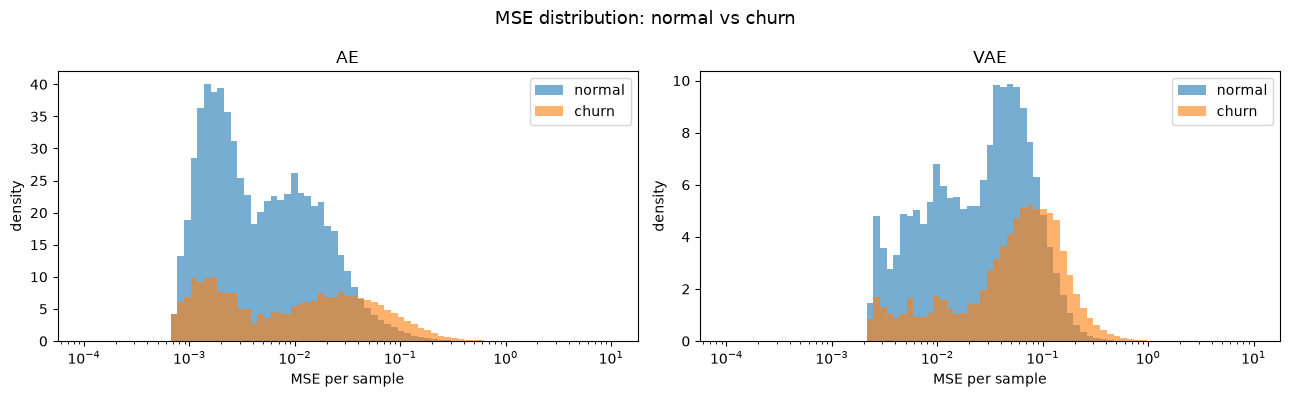

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
bins = np.logspace(np.log10(1e-4), np.log10(10), 80)

for ax, name in zip(axes, ["AE", "VAE"]):
    sub  = ebc[ebc["model"] == name]
    dn   = sub[sub["class"] == "normal"]["mse_per_sample"].values
    dc   = sub[sub["class"] == "churn"]["mse_per_sample"].values
    ax.hist(dn, bins=bins, alpha=0.6, label="normal", density=True)
    ax.hist(dc, bins=bins, alpha=0.6, label="churn",  density=True)
    ax.set_xscale("log"); ax.set_xlabel("MSE per sample"); ax.set_ylabel("density")
    ax.set_title(name); ax.legend()

plt.suptitle("MSE distribution: normal vs churn", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "recon_error_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Per-feature comparison

Top-15 features by VAE MSE:
                    feature   mse_ae  mse_vae  corr_ae  corr_vae  mse_ratio_vae_ae
           expire_dayofweek 0.066914 0.351305 0.962812  0.876379          5.250083
             days_to_expire 0.157058 0.266892 0.939766  0.910519          1.699323
         registration_month 0.013537 0.241045 0.993700  0.967857         17.805972
days_since_last_transaction 0.178886 0.195759 0.916220  0.917481          1.094323
             n_amounts_paid 0.083474 0.181389 0.961039  0.912608          2.173008
                 difference 0.081028 0.177339 0.957052  0.907652          2.188606
        last_third_ratio_25 0.129499 0.176265 0.934267  0.913428          1.361136
           login_difference 0.027691 0.171427 0.987710  0.934109          6.190746
          registration_year 0.048728 0.161395 0.976060  0.923803          3.312173
               more_than_30 0.101397 0.156092 0.952169  0.928154          1.539410
             trend_ratio100 0.065963 0.146218 0.968532  0.9

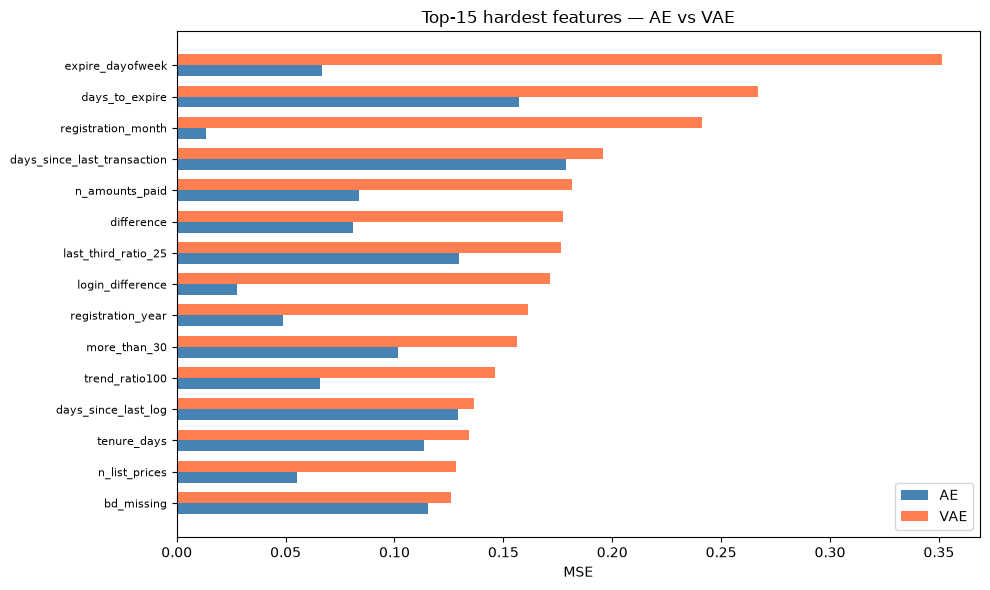

In [7]:
pfc = comp.per_feature_comparison(x_num_test, x_cat_test)
pfc.to_csv(RECON_DIR / "recon_per_feature.csv", index=False)
print("Top-15 features by VAE MSE:")
print(pfc.head(15).to_string(index=False))

top15 = pfc.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(top15))
bar_h = 0.35
ax.barh(y_pos + bar_h/2, top15["mse_ae"],  bar_h, label="AE",  color="steelblue")
ax.barh(y_pos - bar_h/2, top15["mse_vae"], bar_h, label="VAE", color="coral")
ax.set_yticks(y_pos); ax.set_yticklabels(top15["feature"], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("MSE")
ax.set_title("Top-15 hardest features — AE vs VAE"); ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "recon_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Sample panel (4 normal + 4 churn)

In [8]:
DISPLAY_FEATS = [
    "days_to_expire", "days_since_last_transaction", "plan_coverage_ratio",
    "tenure_days", "last_is_auto_renew", "total_secs",
    "city",
]
# Keep only features that exist in feature_names
all_feats = prep.feature_names
display_feats = [f for f in DISPLAY_FEATS if f in all_feats][:7]

panel_rows = comp.select_panel_rows(y_test, n_normal=4, n_churn=4, seed=SEED)
panel_df   = comp.panel_table(panel_rows, x_num_test, x_cat_test, df_test)

panel_sub = panel_df[display_feats + ["source"]].copy()
panel_sub.insert(0, "client", np.tile(np.arange(len(panel_rows)), 3))
panel_sub.insert(1, "label",  np.tile(["normal"]*4 + ["churn"]*4, 3))
panel_sub.to_csv(RECON_DIR / "recon_sample_panel.csv", index=False)

# Print as pivot
print(panel_sub.set_index(["client", "label", "source"])[display_feats].to_string())

                        days_to_expire  days_since_last_transaction  plan_coverage_ratio  tenure_days  last_is_auto_renew  city
client label  source                                                                                                           
0      normal original       11.000000                    17.000000             1.012281   566.000000                 1.0   1.0
1      normal original       31.000000                     0.000000             1.014583  1909.000000                 1.0  13.0
2      normal original       31.000000                     0.000000             1.014583  4092.000000                 1.0  18.0
3      normal original        2.000000                    25.000000             0.900000    33.000000                 1.0   1.0
4      churn  original       31.000000                     0.000000             0.930809  1046.000000                 1.0   8.0
5      churn  original        6.000000                    24.000000             1.014286  1351.000000   

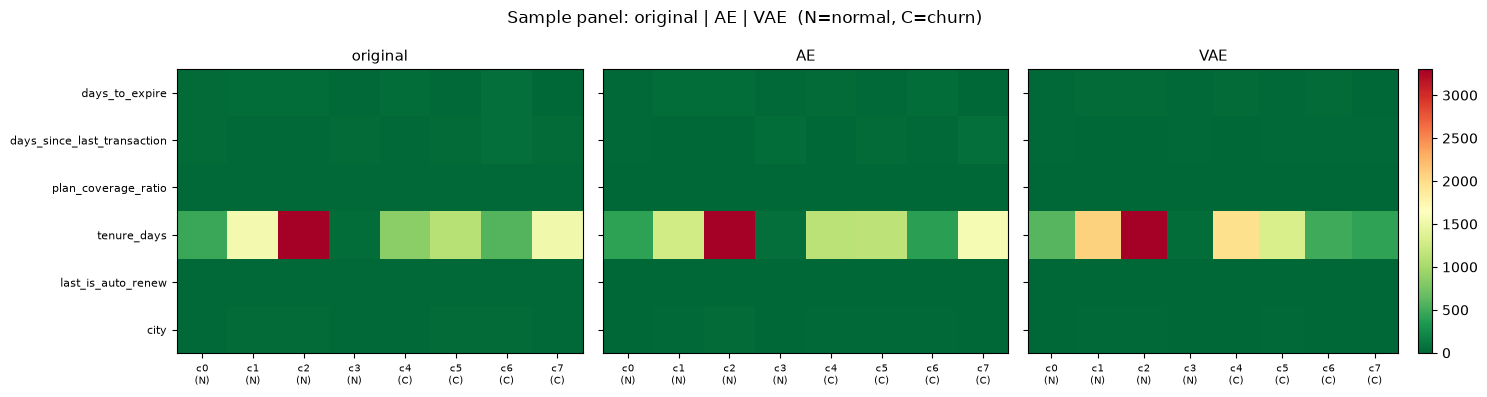

In [9]:
# Visual table figure
sources = ["original", "AE", "VAE"]
n_clients = len(panel_rows)
n_feats   = len(display_feats)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for col, src in enumerate(sources):
    sub  = panel_sub[panel_sub["source"] == src][display_feats]
    vals = sub.to_numpy(dtype=float, na_value=np.nan)
    im   = axes[col].imshow(vals.T, aspect="auto", cmap="RdYlGn_r")
    axes[col].set_title(src, fontsize=11)
    axes[col].set_xticks(range(n_clients))
    axes[col].set_xticklabels(
        [f"c{i}\n({'N' if y_test[panel_rows[i]]==0 else 'C'})" for i in range(n_clients)],
        fontsize=7,
    )
    if col == 0:
        axes[col].set_yticks(range(n_feats))
        axes[col].set_yticklabels(display_feats, fontsize=8)

fig.colorbar(im, ax=axes[-1], fraction=0.04)
plt.suptitle("Sample panel: original | AE | VAE  (N=normal, C=churn)", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "recon_sample_panel.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Difference heatmaps

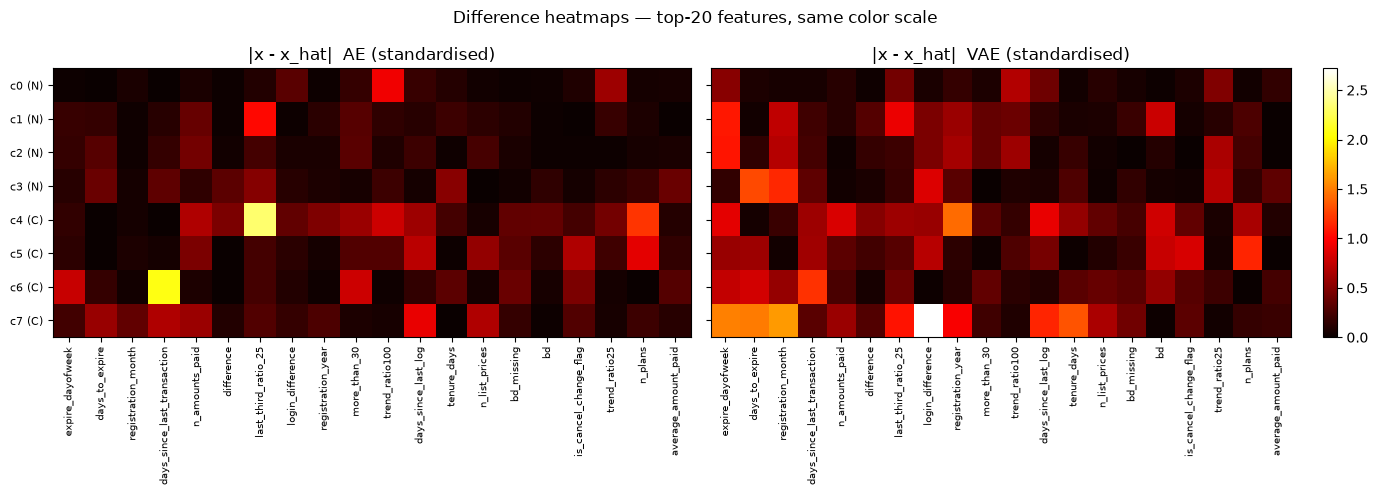

In [10]:
diff_mats = comp.difference_matrices(panel_rows, x_num_test, x_cat_test)

# Use top-20 hardest features (by VAE MSE) for readability
top20_feats = pfc.head(20)["feature"].tolist()

vmax = max(
    diff_mats["AE"][top20_feats].to_numpy().max(),
    diff_mats["VAE"][top20_feats].to_numpy().max(),
)

row_labels = [
    f"c{i} ({'N' if y_test[panel_rows[i]]==0 else 'C'})"
    for i in range(len(panel_rows))
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, name in zip(axes, ["AE", "VAE"]):
    mat = diff_mats[name][top20_feats].to_numpy()
    im  = ax.imshow(mat, aspect="auto", cmap="hot", vmin=0, vmax=vmax)
    ax.set_title(f"|x - x_hat|  {name} (standardised)")
    ax.set_xticks(range(len(top20_feats)))
    ax.set_xticklabels(top20_feats, rotation=90, fontsize=7)
    ax.set_yticks(range(len(panel_rows)))
    ax.set_yticklabels(row_labels, fontsize=8)

fig.colorbar(im, ax=axes[-1], fraction=0.04)
plt.suptitle("Difference heatmaps — top-20 features, same color scale", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "recon_difference_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Numerical summary

In [11]:
ae_row  = summary[summary["model"] == "AE"].iloc[0]
vae_row = summary[summary["model"] == "VAE"].iloc[0]

print("=== Reconstruction quality summary ===")
print(f"MSE global      AE={ae_row['mse_global']:.5f}   VAE={vae_row['mse_global']:.5f}")
print(f"MSE normal      AE={ae_row['mse_normal']:.5f}   VAE={vae_row['mse_normal']:.5f}")
print(f"MSE churn       AE={ae_row['mse_churn']:.5f}    VAE={vae_row['mse_churn']:.5f}")
print(f"Churn/normal    AE={ae_row['churn_to_normal_ratio']:.3f}   VAE={vae_row['churn_to_normal_ratio']:.3f}")
print(f"Mean Pearson    AE={ae_row['mean_pearson']:.4f}   VAE={vae_row['mean_pearson']:.4f}")
print(f"Acc city        AE={ae_row['acc_city']:.4f}   VAE={vae_row['acc_city']:.4f}")

print("\nTop-5 features with highest MSE in both models:")
shared = pfc.head(5)[["feature", "mse_ae", "mse_vae", "mse_ratio_vae_ae"]]
print(shared.to_string(index=False))

=== Reconstruction quality summary ===
MSE global      AE=0.05185   VAE=0.09432
MSE normal      AE=0.04172   VAE=0.08336
MSE churn       AE=0.15431    VAE=0.20521
Churn/normal    AE=3.698   VAE=2.462
Mean Pearson    AE=0.9764   VAE=0.9614
Acc city        AE=0.9998   VAE=0.6603

Top-5 features with highest MSE in both models:
                    feature   mse_ae  mse_vae  mse_ratio_vae_ae
           expire_dayofweek 0.066914 0.351305          5.250083
             days_to_expire 0.157058 0.266892          1.699323
         registration_month 0.013537 0.241045         17.805972
days_since_last_transaction 0.178886 0.195759          1.094323
             n_amounts_paid 0.083474 0.181389          2.173008
